# EDA NextWatch

Analyse exploratoire des donnees MovieLens 100k.

Ce notebook regroupe les analyses des étapes 2, 3 et 4. L'étape 1 sera ajoutée lorsqu'elle sera disponible.

## Étape 1 — Qu'ai-je ?

Avant d'analyser les tendances, on décrit la structure du jeu de données. Cette étape précise le nombre d'observations, les variables disponibles, leurs types et les premiers ordres de grandeur.

### 1. Chargement et aperçu

On charge le DataFrame préparé, puis on observe quelques lignes et un échantillon aléatoire pour comprendre à quoi ressemble une observation.

In [41]:
import pandas as pd
from load_data import load_prepared

df = load_prepared()

print("Premières lignes :")
display(df.head())

print("Échantillon aléatoire :")
display(df.sample(5, random_state=42))


Premières lignes :


,user_id,item_id,rating,timestamp,datetime,date,month,weekday,hour,age,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,release_year
0,196,242,3,881250949,1997-12-04 15:55:49+00:00,1997-12-04,1997-12,Thursday,15,49,...,0,0,0,0,0,0,0,0,0,1997.0
1,186,302,3,891717742,1998-04-04 19:22:22+00:00,1998-04-04,1998-04,Saturday,19,39,...,1,0,0,1,0,0,1,0,0,1997.0
2,22,377,1,878887116,1997-11-07 07:18:36+00:00,1997-11-07,1997-11,Friday,7,25,...,0,0,0,0,0,0,0,0,0,1994.0
3,244,51,2,880606923,1997-11-27 05:02:03+00:00,1997-11-27,1997-11,Thursday,5,28,...,0,0,0,0,1,0,0,1,1,1994.0
4,166,346,1,886397596,1998-02-02 05:33:16+00:00,1998-02-02,1998-02,Monday,5,47,...,0,0,0,0,0,0,0,0,0,1997.0


Échantillon aléatoire :


,user_id,item_id,rating,timestamp,datetime,date,month,weekday,hour,age,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,release_year
75721,877,381,4,882677345,1997-12-21 04:09:05+00:00,1997-12-21,1997-12,Sunday,4,30,...,0,0,0,0,1,0,0,0,0,1994.0
80184,815,602,3,878694269,1997-11-05 01:44:29+00:00,1997-11-05,1997-11,Wednesday,1,32,...,0,0,1,0,1,0,0,0,0,1951.0
19864,94,431,4,891721716,1998-04-04 20:28:36+00:00,1998-04-04,1998-04,Saturday,20,26,...,0,0,0,0,0,0,0,0,0,1986.0
76699,416,875,2,876696938,1997-10-12 22:55:38+00:00,1997-10-12,1997-10,Sunday,22,20,...,0,0,0,0,1,0,0,0,0,1997.0
92991,500,182,2,883873556,1998-01-04 00:25:56+00:00,1998-01-04,1998-01,Sunday,0,28,...,0,0,0,0,0,0,0,0,0,1990.0


### 2. Dimensions et variables

`df.shape` indique le nombre de lignes et de colonnes. `df.columns` permet d'identifier les variables disponibles dans la table fusionnée.

In [42]:
print("Dimensions du DataFrame :", df.shape)

print("Variables disponibles :")
display(pd.DataFrame({"variable": df.columns}))

Dimensions du DataFrame : (100000, 38)
Variables disponibles :


,variable
0,user_id
1,item_id
2,rating
3,timestamp
4,datetime
5,date
6,month
7,weekday
8,hour
9,age


### 3. Types et informations générales

`df.info()` et `df.dtypes` permettent de vérifier les types des colonnes et la présence éventuelle de valeurs manquantes.

In [43]:
print("Informations générales :")
df.info()

print("Types des variables :")
display(df.dtypes.rename("type").to_frame())

Informations générales :
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 38 columns):
 #   Column              Non-Null Count   Dtype             
---  ------              --------------   -----             
 0   user_id             100000 non-null  int64             
 1   item_id             100000 non-null  int64             
 2   rating              100000 non-null  int64             
 3   timestamp           100000 non-null  int64             
 4   datetime            100000 non-null  datetime64[s, UTC]
 5   date                100000 non-null  object            
 6   month               100000 non-null  str               
 7   weekday             100000 non-null  str               
 8   hour                100000 non-null  int32             
 9   age                 100000 non-null  int64             
 10  gender              100000 non-null  str               
 11  occupation          100000 non-null  str               
 12  zip_code         

,type
user_id,int64
item_id,int64
rating,int64
timestamp,int64
datetime,"datetime64[s, UTC]"
date,object
month,str
weekday,str
hour,int32
age,int64


### 4. Premiers ordres de grandeur

`df.describe()` résume les variables numériques avec leur effectif, leur moyenne, leur écart-type, leurs quartiles et leurs valeurs extrêmes.

In [44]:
# Premiers ordres de grandeur sur les variables numériques
description = df.describe().T
display(description)


,count,mean,min,25%,50%,75%,max,std
user_id,100000.0,462.48475,1.0,254.0,447.0,682.0,943.0,266.61442
item_id,100000.0,425.53013,1.0,175.0,322.0,631.0,1682.0,330.798356
rating,100000.0,3.52986,1.0,3.0,4.0,4.0,5.0,1.125674
timestamp,100000.0,883528851.48862,874724710.0,879448709.5,882826944.0,888259984.0,893286638.0,5343856.189503
hour,100000.0,13.05284,0.0,5.0,16.0,20.0,23.0,7.841005
age,100000.0,32.96985,7.0,24.0,30.0,40.0,73.0,11.562623
movie_id,100000.0,425.53013,1.0,175.0,322.0,631.0,1682.0,330.798356
release_date,99991,1988-02-09 00:43:11.369223,1922-01-01 00:00:00,1986-01-01 00:00:00,1994-01-01 00:00:00,1996-09-28 00:00:00,1998-10-23 00:00:00,NaN
video_release_date,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unknown,100000.0,0.0001,0.0,0.0,0.0,0.0,1.0,0.01


### 5. Conclusion

Cette description donne le cadre de l'analyse : le DataFrame contient les évaluations, les informations utilisateurs et les informations films. Les étapes suivantes pourront donc étudier sa qualité puis les tendances observées.

In [ ]:
print("Conclusion :")
print(f"Le jeu de données contient {df.shape[0]:,} lignes et {df.shape[1]} colonnes.")
print("Il rassemble les notes, les utilisateurs et les films dans un même DataFrame.")

## Étape 2 — Puis-je faire confiance aux données ?

On vérifie les valeurs manquantes, les doublons, les catégories, les min/max/quantiles ainsi que la cohérence des dates, des unités et des types.


## Objectif de l'étape 2

La question est : **puis-je faire confiance aux données ?**

Nous vérifions les valeurs manquantes, les doublons, les catégories, les valeurs numériques et la cohérence des dates, des unités et des types avant de commencer l'analyse.\n

### 1. Chargement et aperçu

On charge le DataFrame préparé et on observe ses dimensions ainsi que ses premières lignes. Cela permet de vérifier que le jeu de données attendu est bien utilisé.\n

In [33]:
import pandas as pd
from load_data import load_prepared

df = load_prepared()
df.head()
print("Dimensions :", df.shape)


Dimensions : (100000, 38)


### 2. Valeurs manquantes

`df.isna().sum()` permet d'identifier les colonnes incomplètes. Le pourcentage est ajouté pour mesurer l'importance de chaque manque et décider s'il faut le traiter.\n

In [34]:
# Valeurs manquantes : que manque-t-il ?
missing = (
    df.isna().sum()
      .rename("n_manquants")
      .to_frame()
      .assign(pourcentage=lambda x: (100 * x["n_manquants"] / len(df)).round(2))
      .query("n_manquants > 0")
      .sort_values("n_manquants", ascending=False)
)
display(missing)


,n_manquants,pourcentage
video_release_date,100000,100.00
imdb_url,13,0.01
release_date,9,0.01
release_year,9,0.01


### 3. Doublons

On recherche les doublons sur toute la ligne et sur le couple **utilisateur-film**. Dans ce jeu de données, un même utilisateur ne doit noter un film qu'une seule fois.\n

In [35]:
# Doublons : y a-t-il des lignes répétées ?
duplicates = pd.DataFrame({
    "doublons_complets": [int(df.duplicated().sum())],
    "doublons_user_film": [int(df.duplicated(["user_id", "item_id"]).sum())],
})
display(duplicates)


,doublons_complets,doublons_user_film
0,0,0


### 4. Catégories et modalités

`nunique()` indique le nombre de modalités différentes et `value_counts()` leur répartition. On vérifie ainsi les valeurs étranges dans le sexe, le métier et les notes.\n

In [36]:
# Catégories : les valeurs sont-elles cohérentes ?
category_summary = pd.DataFrame({
    "colonne": ["gender", "occupation", "rating"],
    "nunique": [
        int(df["gender"].nunique(dropna=True)),
        int(df["occupation"].nunique(dropna=True)),
        int(df["rating"].nunique(dropna=True)),
    ],
    "valeurs": [
        ", ".join(sorted(df["gender"].dropna().astype(str).unique())),
        ", ".join(sorted(df["occupation"].dropna().astype(str).unique())),
        ", ".join(str(value) for value in sorted(df["rating"].dropna().unique())),
    ],
})
display(category_summary)
display(df["gender"].value_counts(dropna=False).rename_axis("gender").to_frame("effectif"))
display(df["rating"].value_counts(dropna=False).sort_index().rename_axis("rating").to_frame("effectif"))


,colonne,nunique,valeurs
0,gender,2,"F, M"
1,occupation,21,"administrator, artist, doctor, educator, engin..."
2,rating,5,"1, 2, 3, 4, 5"


,effectif
gender,
M,74260
F,25740


,effectif
rating,
1,6110
2,11370
3,27145
4,34174
5,21201


### 5. Min, max, quantiles et incohérences

Les statistiques descriptives permettent de repérer les valeurs impossibles ou surprenantes. Les contrôles comparent ensuite les résultats à des bornes plausibles pour les notes, les âges, les années et les timestamps.\n

In [37]:
# Min, max et quantiles : valeurs impossibles ou surprenantes ?
numeric_columns = ["rating", "age", "timestamp", "release_year"]
numeric_summary = df[numeric_columns].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
numeric_summary = numeric_summary[["min", "1%", "25%", "50%", "75%", "99%", "max"]]
display(numeric_summary)

range_checks = pd.DataFrame({
    "controle": [
        "notes hors de l'intervalle [1, 5]",
        "âges hors de l'intervalle plausible [1, 120]",
        "années de sortie hors [1888, année actuelle]",
        "timestamps négatifs",
        "dates converties invalides",
    ],
    "effectif": [
        int((df["rating"].notna() & ~df["rating"].between(1, 5)).sum()),
        int((df["age"].notna() & ~df["age"].between(1, 120)).sum()),
        int((df["release_year"].notna() & ~df["release_year"].between(1888, pd.Timestamp.now().year)).sum()),
        int((df["timestamp"].notna() & (df["timestamp"] < 0)).sum()),
        int(df["datetime"].isna().sum()),
    ],
})
display(range_checks)


,min,1%,25%,50%,75%,99%,max
rating,1.0,1.0,3.0,4.0,4.0,5.0,5.0
age,7.0,15.0,24.0,30.0,40.0,61.0,73.0
timestamp,874724710.0,874825826.0,879448709.5,882826944.0,888259984.0,892911494.0,893286638.0
release_year,1922.0,1939.0,1986.0,1994.0,1996.0,1997.0,1998.0


,controle,effectif
0,"notes hors de l'intervalle [1, 5]",0
1,"âges hors de l'intervalle plausible [1, 120]",0
2,"années de sortie hors [1888, année actuelle]",0
3,timestamps négatifs,0
4,dates converties invalides,0


### 6. Dates, unités et types

On vérifie les types de colonnes avec `df.dtypes` et les bornes temporelles. Le timestamp est exprimé en secondes Unix, tandis que `datetime` doit être une date exploitable.\n

In [38]:
# Dates, unités et types : sont-ils cohérents ?
type_summary = df.dtypes.astype(str).rename("type").to_frame()
display(type_summary)

date_summary = pd.DataFrame({
    "indicateur": [
        "timestamp min",
        "timestamp max",
        "date min",
        "date max",
        "années de sortie manquantes",
    ],
    "valeur": [
        df["timestamp"].min(),
        df["timestamp"].max(),
        df["datetime"].min(),
        df["datetime"].max(),
        int(df["release_year"].isna().sum()),
    ],
})
display(date_summary)


,type
user_id,int64
item_id,int64
rating,int64
timestamp,int64
datetime,"datetime64[s, UTC]"
date,object
month,str
weekday,str
hour,int32
age,int64


,indicateur,valeur
0,timestamp min,874724710
1,timestamp max,893286638
2,date min,1997-09-20 03:05:10+00:00
3,date max,1998-04-22 23:10:38+00:00
4,années de sortie manquantes,9


### 7. Conclusion

Ces contrôles ne suppriment aucune donnée automatiquement. Ils servent à documenter la qualité du jeu de données et à signaler les points à prendre en compte dans les étapes 3 et 4.\n

In [39]:
print("Conclusion :")
print("- Les valeurs manquantes, les doublons et les catégories ont été vérifiés.")
print("- Les min, max et quantiles permettent de repérer les valeurs impossibles ou atypiques.")
print("- Les dates, les unités et les types sont contrôlés avant les étapes 3 et 4.")
print("- Les valeurs manquantes de release_date et release_year correspondent à des dates absentes du catalogue.")


Conclusion :
- Les valeurs manquantes, les doublons et les catégories ont été vérifiés.
- Les min, max et quantiles permettent de repérer les valeurs impossibles ou atypiques.
- Les dates, les unités et les types sont contrôlés avant les étapes 3 et 4.
- Les valeurs manquantes de release_date et release_year correspondent à des dates absentes du catalogue.


In [31]:
import pandas as pd

from load_data import load_prepared

df = load_prepared()
df.head()


,user_id,item_id,rating,timestamp,datetime,date,month,weekday,hour,age,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,release_year
0,196,242,3,881250949,1997-12-04 15:55:49+00:00,1997-12-04,1997-12,Thursday,15,49,...,0,0,0,0,0,0,0,0,0,1997.0
1,186,302,3,891717742,1998-04-04 19:22:22+00:00,1998-04-04,1998-04,Saturday,19,39,...,1,0,0,1,0,0,1,0,0,1997.0
2,22,377,1,878887116,1997-11-07 07:18:36+00:00,1997-11-07,1997-11,Friday,7,25,...,0,0,0,0,0,0,0,0,0,1994.0
3,244,51,2,880606923,1997-11-27 05:02:03+00:00,1997-11-27,1997-11,Thursday,5,28,...,0,0,0,0,1,0,0,1,1,1994.0
4,166,346,1,886397596,1998-02-02 05:33:16+00:00,1998-02-02,1998-02,Monday,5,47,...,0,0,0,0,0,0,0,0,0,1997.0


### Contrôles de qualité


# Étape 3 — Lilian

# Étape 3 — Lilian

## Objectif final

Comprendre **l’appréciation des films** (notes) en lien avec :

- le **genre du film** ;
- l’**âge**, le **sexe** et le **métier** des utilisateurs.

## Démarche

On commence large (vue d’ensemble, distributions, volumes), puis on raffine (groupes, croisements), et on termine par des **corrélations** sur des indicateurs numériques dérivés.

1. Chargement  
2. Vue d’ensemble du jeu de données  
3. Variables numériques  
4. Variables catégorielles  
5. Dimension temporelle (contexte)  
6. Activité des utilisateurs / popularité des films  
7. Appréciation selon genre de film, âge, sexe, métier  
8. Croisements  
9. Corrélations  
10. Synthèse

## 0. Chargement et préparation

Script commun : [`load_data.py`](load_data.py).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from load_data import GENRES, load_prepared

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

df = load_prepared()
notes = df
users = df.drop_duplicates("user_id")
films = df.drop_duplicates("movie_id")

df["age_bin"] = pd.cut(
    df["age"],
    bins=[0, 17, 24, 34, 44, 54, 100],
    labels=["≤17", "18-24", "25-34", "35-44", "45-54", "55+"],
)

# Indicateurs utiles plus loin (activité / popularité)
user_activity = (
    df.groupby("user_id", as_index=False)
      .agg(
          n_notes=("rating", "size"),
          note_moyenne=("rating", "mean"),
          note_std=("rating", "std"),
          age=("age", "first"),
          gender=("gender", "first"),
          occupation=("occupation", "first"),
      )
)

film_popularity = (
    df.groupby(["item_id", "title"], as_index=False)
      .agg(
          n_notes=("rating", "size"),
          note_moyenne=("rating", "mean"),
          note_std=("rating", "std"),
          release_year=("release_year", "first"),
      )
)

df.head()

,user_id,item_id,rating,timestamp,datetime,date,month,weekday,hour,age,...,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,release_year,age_bin
0,196,242,3,881250949,1997-12-04 15:55:49+00:00,1997-12-04,1997-12,Thursday,15,49,...,0,0,0,0,0,0,0,0,1997.0,45-54
1,186,302,3,891717742,1998-04-04 19:22:22+00:00,1998-04-04,1998-04,Saturday,19,39,...,0,0,1,0,0,1,0,0,1997.0,35-44
2,22,377,1,878887116,1997-11-07 07:18:36+00:00,1997-11-07,1997-11,Friday,7,25,...,0,0,0,0,0,0,0,0,1994.0,25-34
3,244,51,2,880606923,1997-11-27 05:02:03+00:00,1997-11-27,1997-11,Thursday,5,28,...,0,0,0,1,0,0,1,1,1994.0,25-34
4,166,346,1,886397596,1998-02-02 05:33:16+00:00,1998-02-02,1998-02,Monday,5,47,...,0,0,0,0,0,0,0,0,1997.0,45-54


## 1. Vue d’ensemble

Tailles, types, manquants, premiers ordres de grandeur — avant toute analyse fine.

In [2]:
print("=== Tailles ===")
print(f"Notes (interactions) : {len(notes):,}")
print(f"Utilisateurs         : {len(users):,}")
print(f"Films                : {len(films):,}")
print(f"Table fusionnée df   : {df.shape}")
print(f"Notes / utilisateur  : {len(notes) / len(users):.1f} en moyenne")
print(f"Notes / film         : {len(notes) / len(films):.1f} en moyenne")

print("\n=== Colonnes clés de df ===")
display(df[["user_id", "item_id", "rating", "age", "gender", "occupation", "title"]].dtypes.to_frame("dtype"))

print("\n=== Valeurs manquantes (colonnes utiles) ===")
cols_check = ["rating", "age", "gender", "occupation", "release_date", "release_year", "title"]
display(df[cols_check].isna().sum().to_frame("n_na").assign(pct=lambda x: (100 * x["n_na"] / len(df)).round(2)))

=== Tailles ===
Notes (interactions) : 100,000
Utilisateurs         : 943
Films                : 1,682
Table fusionnée df   : (100000, 39)
Notes / utilisateur  : 106.0 en moyenne
Notes / film         : 59.5 en moyenne

=== Colonnes clés de df ===


,dtype
user_id,int64
item_id,int64
rating,int64
age,int64
gender,str
occupation,str
title,str



=== Valeurs manquantes (colonnes utiles) ===


,n_na,pct
rating,0,0.00
age,0,0.00
gender,0,0.00
occupation,0,0.00
release_date,9,0.01
release_year,9,0.01
title,0,0.00


In [3]:
print("Aperçu notes :")
display(notes.head(3))
print("Aperçu users :")
display(users.head(3))
print("Aperçu films (id, titre, année + 5 genres) :")
display(films[["movie_id", "title", "release_year"] + GENRES[:5]].head(3))

Aperçu notes :


,user_id,item_id,rating,timestamp,datetime,date,month,weekday,hour,age,...,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,release_year,age_bin
0,196,242,3,881250949,1997-12-04 15:55:49+00:00,1997-12-04,1997-12,Thursday,15,49,...,0,0,0,0,0,0,0,0,1997.0,45-54
1,186,302,3,891717742,1998-04-04 19:22:22+00:00,1998-04-04,1998-04,Saturday,19,39,...,0,0,1,0,0,1,0,0,1997.0,35-44
2,22,377,1,878887116,1997-11-07 07:18:36+00:00,1997-11-07,1997-11,Friday,7,25,...,0,0,0,0,0,0,0,0,1994.0,25-34


Aperçu users :


,user_id,item_id,rating,timestamp,datetime,date,month,weekday,hour,age,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,release_year
0,196,242,3,881250949,1997-12-04 15:55:49+00:00,1997-12-04,1997-12,Thursday,15,49,...,0,0,0,0,0,0,0,0,0,1997.0
1,186,302,3,891717742,1998-04-04 19:22:22+00:00,1998-04-04,1998-04,Saturday,19,39,...,1,0,0,1,0,0,1,0,0,1997.0
2,22,377,1,878887116,1997-11-07 07:18:36+00:00,1997-11-07,1997-11,Friday,7,25,...,0,0,0,0,0,0,0,0,0,1994.0


Aperçu films (id, titre, année + 5 genres) :


,movie_id,title,release_year,unknown,Action,Adventure,Animation,Children's
0,242,Kolya (1996),1997.0,0,0,0,0,0
1,302,L.A. Confidential (1997),1997.0,0,0,0,0,0
2,377,Heavyweights (1994),1994.0,0,0,0,0,1


## 2. Variables numériques — description large

Moyenne, médiane, quantiles, histogrammes, boxplots sur `rating`, `age`, et les volumes d’activité.

In [4]:
def describe_numeric(series: pd.Series, name: str) -> pd.DataFrame:
    base = series.agg(["count", "mean", "median", "std", "min", "max"])
    q = series.quantile([0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
    q.index = [f"q{int(i*100)}" for i in q.index]
    out = pd.concat([base, q]).to_frame(name).T
    return out

stats_rating = describe_numeric(df["rating"], "rating")
stats_age = describe_numeric(users["age"], "age")
stats_n_user = describe_numeric(user_activity["n_notes"], "n_notes_par_user")
stats_n_film = describe_numeric(film_popularity["n_notes"], "n_notes_par_film")

stats_num = pd.concat([stats_rating, stats_age, stats_n_user, stats_n_film])
display(stats_num.round(3))

,count,mean,median,std,min,max,q5,q25,q50,q75,q90,q95,q99
rating,100000.0,3.530,4.0,1.126,1.0,5.0,1.0,3.0,4.0,4.0,5.0,5.00,5.00
age,943.0,34.052,31.0,12.193,7.0,73.0,18.0,25.0,31.0,43.0,51.0,56.00,65.00
n_notes_par_user,943.0,106.045,65.0,100.932,20.0,737.0,21.0,33.0,65.0,148.0,244.4,310.60,442.54
n_notes_par_film,1682.0,59.453,27.0,80.384,1.0,583.0,1.0,6.0,27.0,80.0,169.0,229.85,369.09


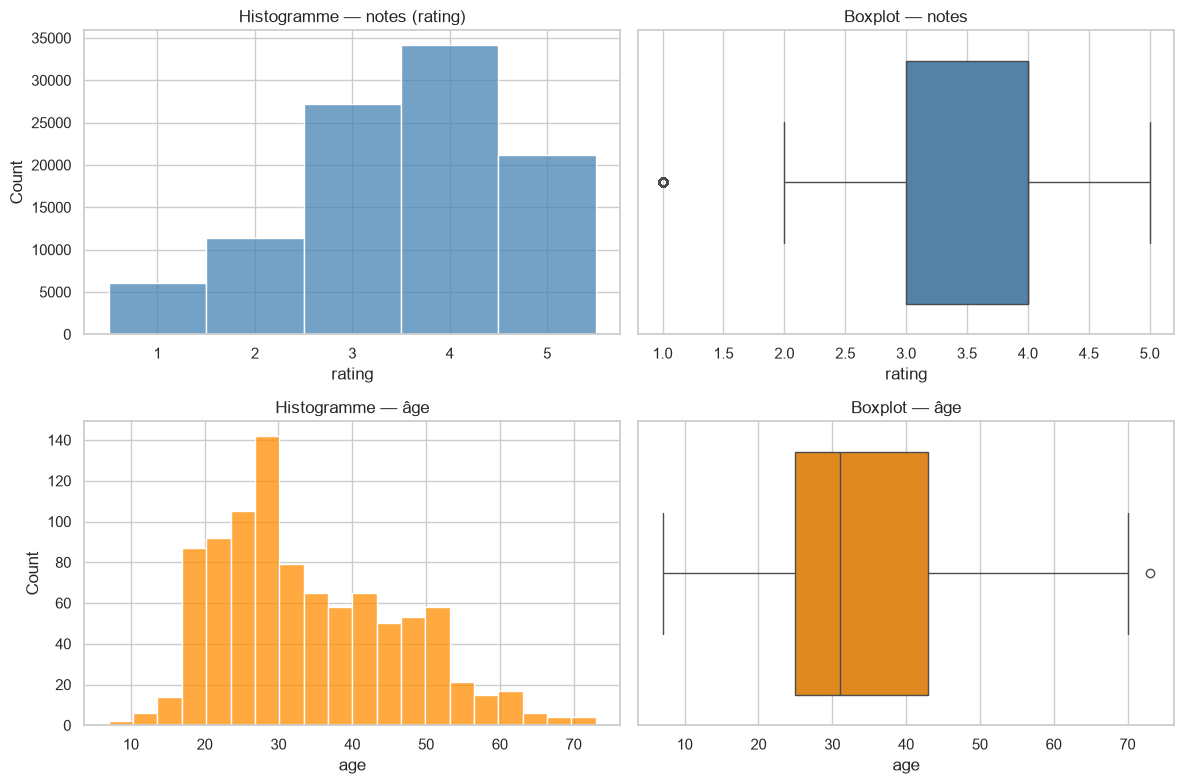

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["rating"], bins=5, discrete=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Histogramme — notes (rating)")

sns.boxplot(x=df["rating"], ax=axes[0, 1], color="steelblue")
axes[0, 1].set_title("Boxplot — notes")

sns.histplot(users["age"], bins=20, ax=axes[1, 0], color="darkorange")
axes[1, 0].set_title("Histogramme — âge")

sns.boxplot(x=users["age"], ax=axes[1, 1], color="darkorange")
axes[1, 1].set_title("Boxplot — âge")

plt.tight_layout()
plt.show()

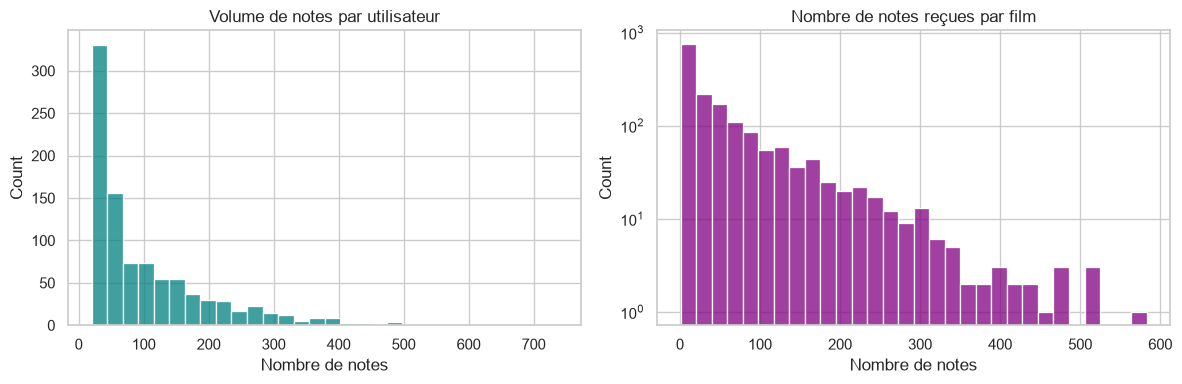

Top 10 films les plus notés :


,title,n_notes,note_moyenne
49,Star Wars (1977),583,4.358491
257,Contact (1997),509,3.803536
99,Fargo (1996),508,4.155512
180,Return of the Jedi (1983),507,4.007890
293,Liar Liar (1997),485,3.156701
285,"English Patient, The (1996)",481,3.656965
287,Scream (1996),478,3.441423
0,Toy Story (1995),452,3.878319
299,Air Force One (1997),431,3.631090
120,Independence Day (ID4) (1996),429,3.438228


Top 10 utilisateurs les plus actifs :


,user_id,n_notes,note_moyenne,age,occupation
404,405,737,1.834464,22,healthcare
654,655,685,2.908029,50,healthcare
12,13,636,3.097484,47,educator
449,450,540,3.864815,35,educator
275,276,518,3.465251,21,student
415,416,493,3.845842,20,student
536,537,490,2.865306,36,engineer
302,303,484,3.365702,19,student
233,234,480,3.122917,60,retired
392,393,448,3.337054,19,student


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(user_activity["n_notes"], bins=30, ax=axes[0], color="teal")
axes[0].set_title("Volume de notes par utilisateur")
axes[0].set_xlabel("Nombre de notes")

sns.histplot(film_popularity["n_notes"], bins=30, ax=axes[1], color="purple")
axes[1].set_title("Nombre de notes reçues par film")
axes[1].set_xlabel("Nombre de notes")
axes[1].set_yscale("log")

plt.tight_layout()
plt.show()

print("Top 10 films les plus notés :")
display(film_popularity.nlargest(10, "n_notes")[["title", "n_notes", "note_moyenne"]])
print("Top 10 utilisateurs les plus actifs :")
display(user_activity.nlargest(10, "n_notes")[["user_id", "n_notes", "note_moyenne", "age", "occupation"]])

## 3. Variables catégorielles — effectifs et raretés

Sexe, métier, genres de films : proportions et catégories rares.

In [7]:
def summary_cat(series: pd.Series, name: str) -> pd.DataFrame:
    counts = series.value_counts(dropna=False)
    props = series.value_counts(normalize=True, dropna=False)
    out = pd.DataFrame({"effectif": counts, "proportion": props})
    out.index.name = name
    return out

gender_summary = summary_cat(users["gender"], "gender")
occupation_summary = summary_cat(users["occupation"], "occupation")
age_bin_summary = summary_cat(df.drop_duplicates("user_id")["age_bin"], "age_bin")

display(gender_summary)
display(age_bin_summary)
display(occupation_summary)

print("Métiers rares (< 2 % des utilisateurs) :")
display(occupation_summary[occupation_summary["proportion"] < 0.02])

,effectif,proportion
gender,,
M,670,0.710498
F,273,0.289502


,effectif,proportion
age_bin,,
25-34,310,0.328738
18-24,198,0.209968
35-44,194,0.205726
45-54,142,0.150583
55+,63,0.066808
≤17,36,0.038176


,effectif,proportion
occupation,,
student,196,0.207847
other,105,0.111347
educator,95,0.100742
administrator,79,0.083775
engineer,67,0.071050
programmer,66,0.069989
librarian,51,0.054083
writer,45,0.047720
executive,32,0.033934


Métiers rares (< 2 % des utilisateurs) :


,effectif,proportion
occupation,,
entertainment,18,0.019088
healthcare,16,0.016967
retired,14,0.014846
lawyer,12,0.012725
salesman,12,0.012725
none,9,0.009544
doctor,7,0.007423
homemaker,7,0.007423


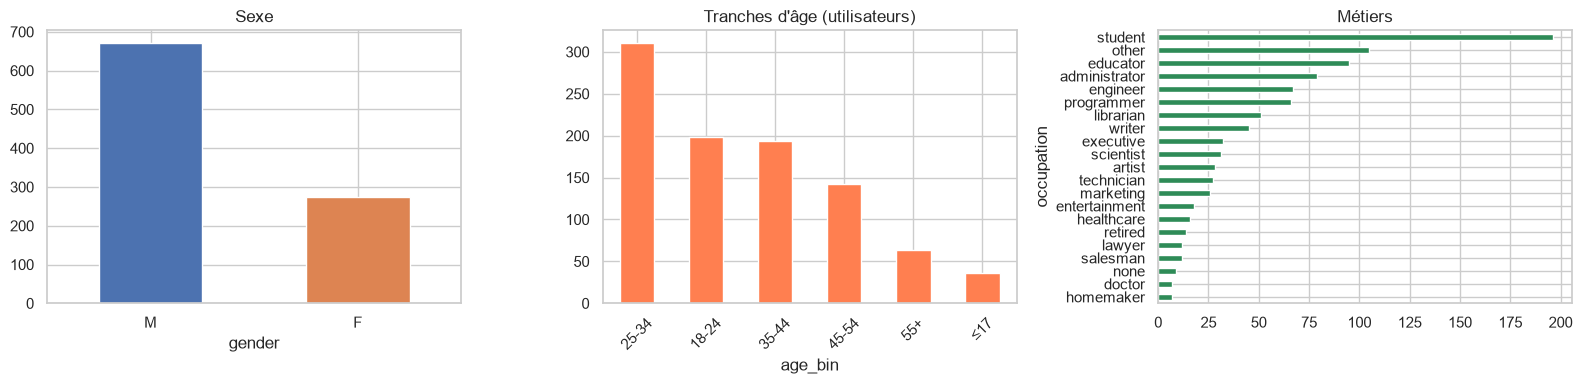

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

gender_summary["effectif"].plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Sexe")
axes[0].tick_params(axis="x", rotation=0)

age_bin_summary["effectif"].plot(kind="bar", ax=axes[1], color="coral")
axes[1].set_title("Tranches d'âge (utilisateurs)")
axes[1].tick_params(axis="x", rotation=45)

occupation_summary["effectif"].sort_values().plot(kind="barh", ax=axes[2], color="seagreen")
axes[2].set_title("Métiers")

plt.tight_layout()
plt.show()

,n_films,proportion_films,n_notes,proportion_notes
Drama,725,0.431034,39895,0.39895
Comedy,505,0.300238,29832,0.29832
Action,251,0.149227,25589,0.25589
Thriller,251,0.149227,21872,0.21872
Romance,247,0.146849,19461,0.19461
Adventure,135,0.080262,13753,0.13753
Sci-Fi,101,0.060048,12730,0.12730
War,71,0.042212,9398,0.09398
Crime,109,0.064804,8055,0.08055
Children's,122,0.072533,7182,0.07182


Genres rares (< 3 % des films) :


,n_films,proportion_films,n_notes,proportion_notes
Documentary,50,0.029727,758,0.00758
Animation,42,0.024970,3605,0.03605
Western,27,0.016052,1854,0.01854
Film-Noir,24,0.014269,1733,0.01733
Fantasy,22,0.013080,1352,0.01352
unknown,2,0.001189,10,0.00010


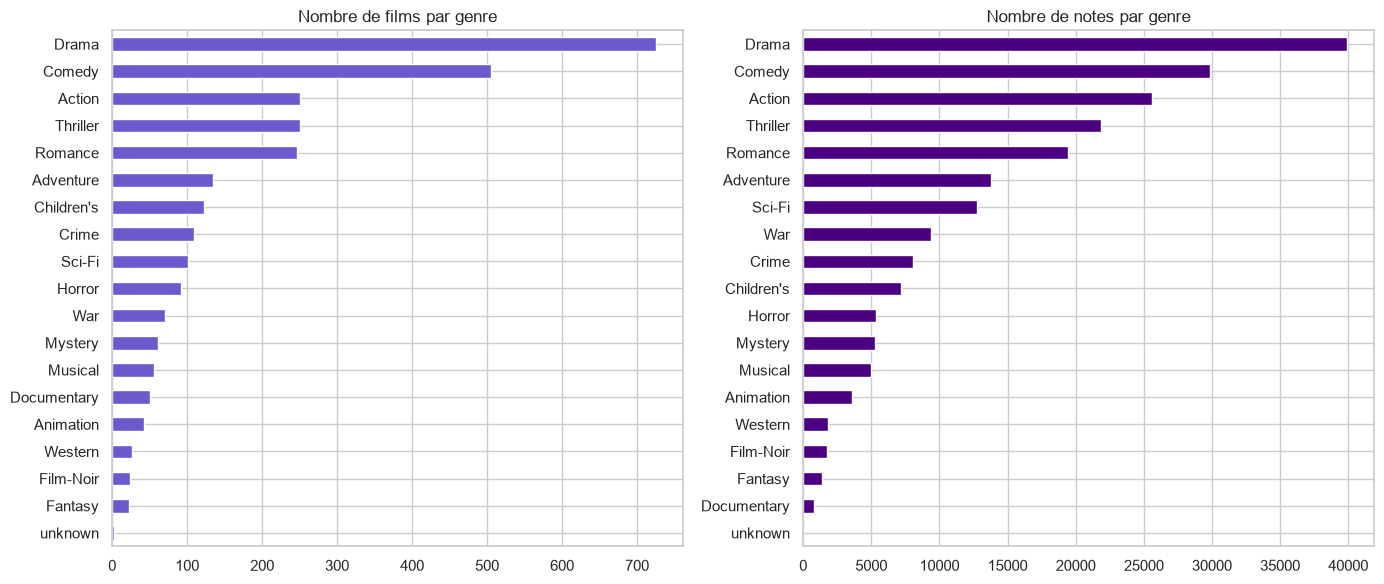

Nombre de genres par film :


,n_films
1,833
2,569
3,215
4,51
5,11
6,3


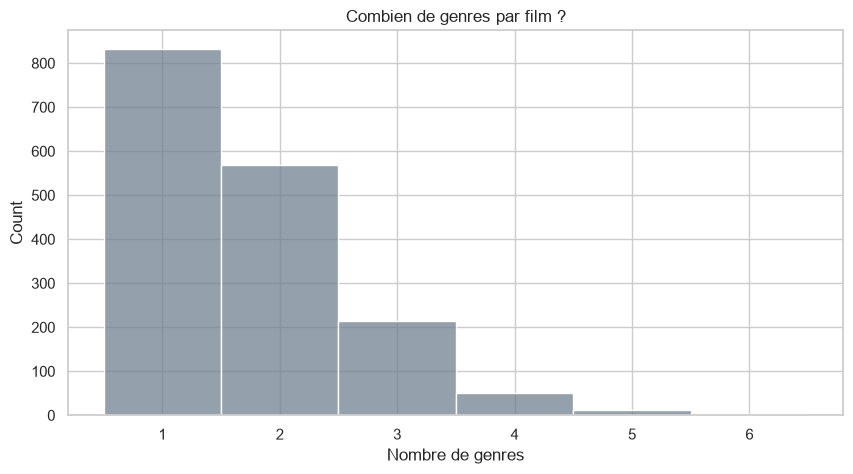

In [9]:
genre_counts = films[GENRES].sum().sort_values(ascending=False)
genre_summary = pd.DataFrame({
    "n_films": genre_counts,
    "proportion_films": genre_counts / len(films),
})
# Combien de notes touchent chaque genre ?
genre_notes = {g: int((df[g] == 1).sum()) for g in GENRES}
genre_summary["n_notes"] = pd.Series(genre_notes)
genre_summary["proportion_notes"] = genre_summary["n_notes"] / len(df)
display(genre_summary.sort_values("n_notes", ascending=False))

print("Genres rares (< 3 % des films) :")
display(genre_summary[genre_summary["proportion_films"] < 0.03])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
genre_summary["n_films"].sort_values().plot(kind="barh", ax=axes[0], color="slateblue")
axes[0].set_title("Nombre de films par genre")
genre_summary["n_notes"].sort_values().plot(kind="barh", ax=axes[1], color="indigo")
axes[1].set_title("Nombre de notes par genre")
plt.tight_layout()
plt.show()

# Multi-appartenance : un film a souvent plusieurs genres
n_genres_per_film = films[GENRES].sum(axis=1)
print("Nombre de genres par film :")
display(n_genres_per_film.value_counts().sort_index().to_frame("n_films"))
sns.histplot(n_genres_per_film, discrete=True, color="slategray")
plt.title("Combien de genres par film ?")
plt.xlabel("Nombre de genres")
plt.show()

## 4. Dimension temporelle (contexte)

Évolution du volume de notes, saisonnalité, années de sortie des films — pour situer le dataset dans le temps.

Période : 1997-09-20 03:05:10+00:00 → 1998-04-22 23:10:38+00:00


,month,n_notes,note_moyenne,variation_pct
0,1997-09,6704,3.540125,NaN
1,1997-10,10304,3.591421,53.699284
2,1997-11,23980,3.559842,132.725155
3,1997-12,11911,3.580388,-50.329441
4,1998-01,14095,3.397730,18.335992
5,1998-02,10991,3.455009,-22.021994
6,1998-03,12656,3.548831,15.148758
7,1998-04,9359,3.574848,-26.050885


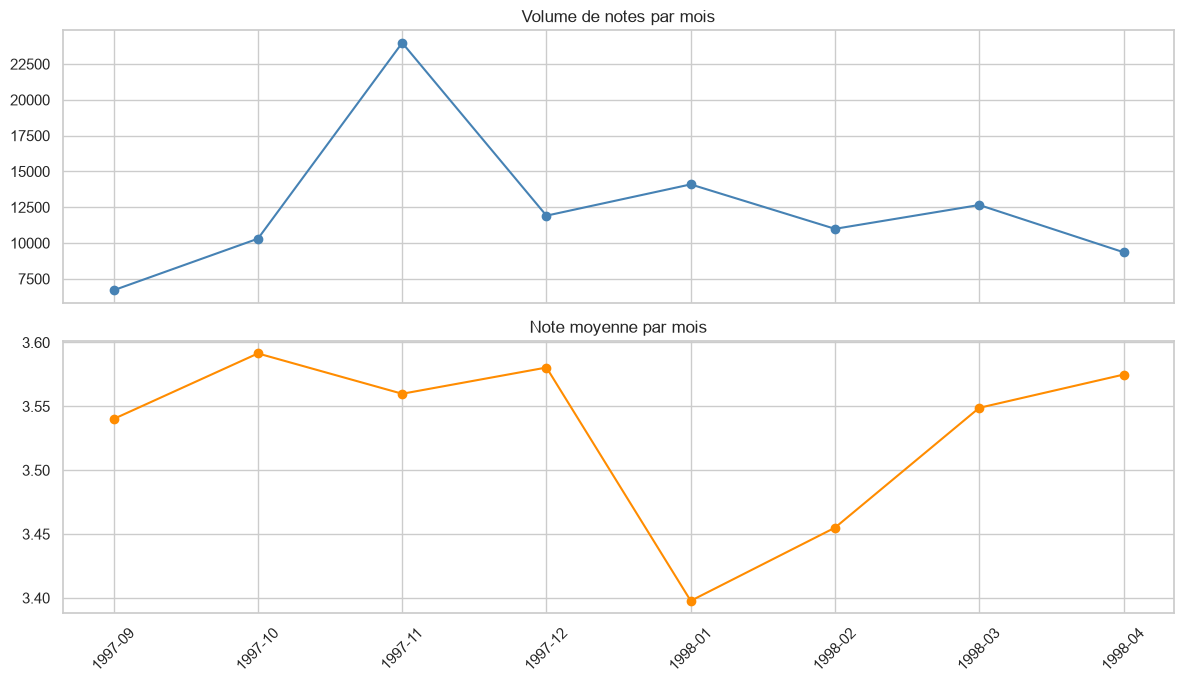

In [10]:
monthly = (
    notes.groupby("month", as_index=False)
         .agg(n_notes=("rating", "size"), note_moyenne=("rating", "mean"))
)
monthly["variation_pct"] = monthly["n_notes"].pct_change() * 100

print("Période :", notes["datetime"].min(), "→", notes["datetime"].max())
display(monthly)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(monthly["month"], monthly["n_notes"], marker="o", color="steelblue")
axes[0].set_title("Volume de notes par mois")
axes[0].tick_params(axis="x", rotation=45)
axes[1].plot(monthly["month"], monthly["note_moyenne"], marker="o", color="darkorange")
axes[1].set_title("Note moyenne par mois")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

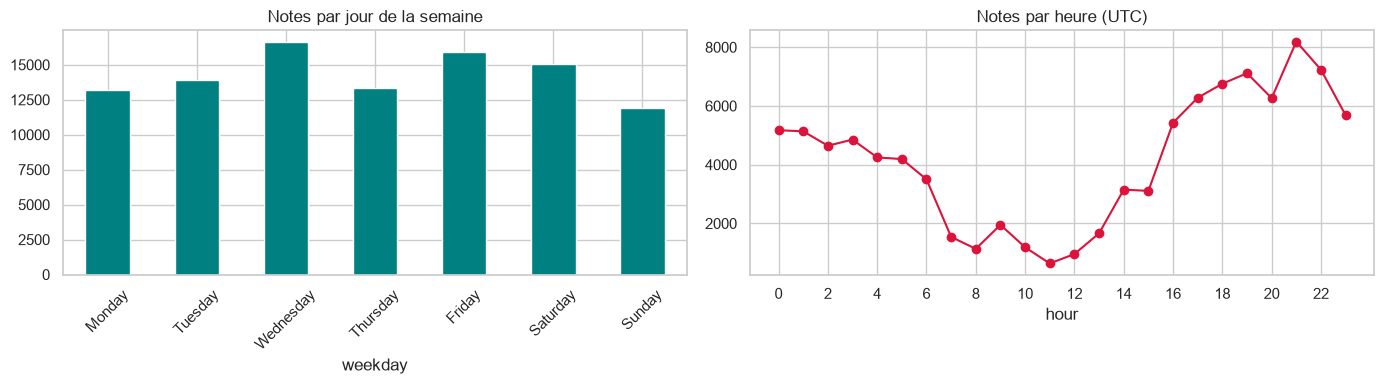

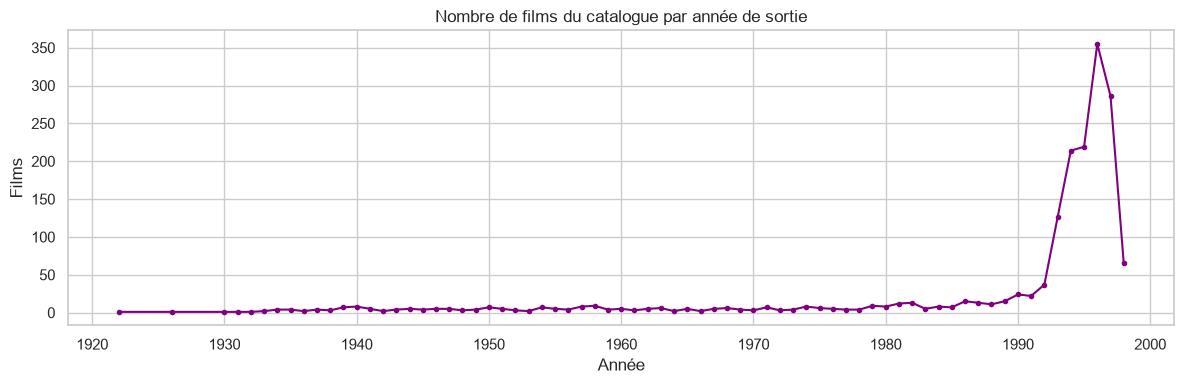

In [11]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_weekday = notes.groupby("weekday").size().reindex(weekday_order)
by_hour = notes.groupby("hour").size()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_weekday.plot(kind="bar", ax=axes[0], color="teal")
axes[0].set_title("Notes par jour de la semaine")
axes[0].tick_params(axis="x", rotation=45)
by_hour.plot(kind="line", marker="o", ax=axes[1], color="crimson")
axes[1].set_title("Notes par heure (UTC)")
axes[1].set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

films_year = films.dropna(subset=["release_year"]).groupby("release_year").size()
films_year.plot(kind="line", figsize=(12, 4), marker=".", color="purple")
plt.title("Nombre de films du catalogue par année de sortie")
plt.xlabel("Année")
plt.ylabel("Films")
plt.tight_layout()
plt.show()

## 5. Appréciation selon le genre du film

Premier facteur cible : quels genres sont les mieux / moins bien notés ?

,n_notes,note_moyenne,note_mediane,note_std
Film-Noir,1733.0,3.922,4.0,0.993
War,9398.0,3.816,4.0,1.080
Drama,39895.0,3.687,4.0,1.079
Documentary,758.0,3.673,4.0,1.180
Mystery,5245.0,3.638,4.0,1.091
Crime,8055.0,3.632,4.0,1.113
Romance,19461.0,3.622,4.0,1.096
Western,1854.0,3.613,4.0,1.042
Animation,3605.0,3.577,4.0,1.097
Sci-Fi,12730.0,3.561,4.0,1.133


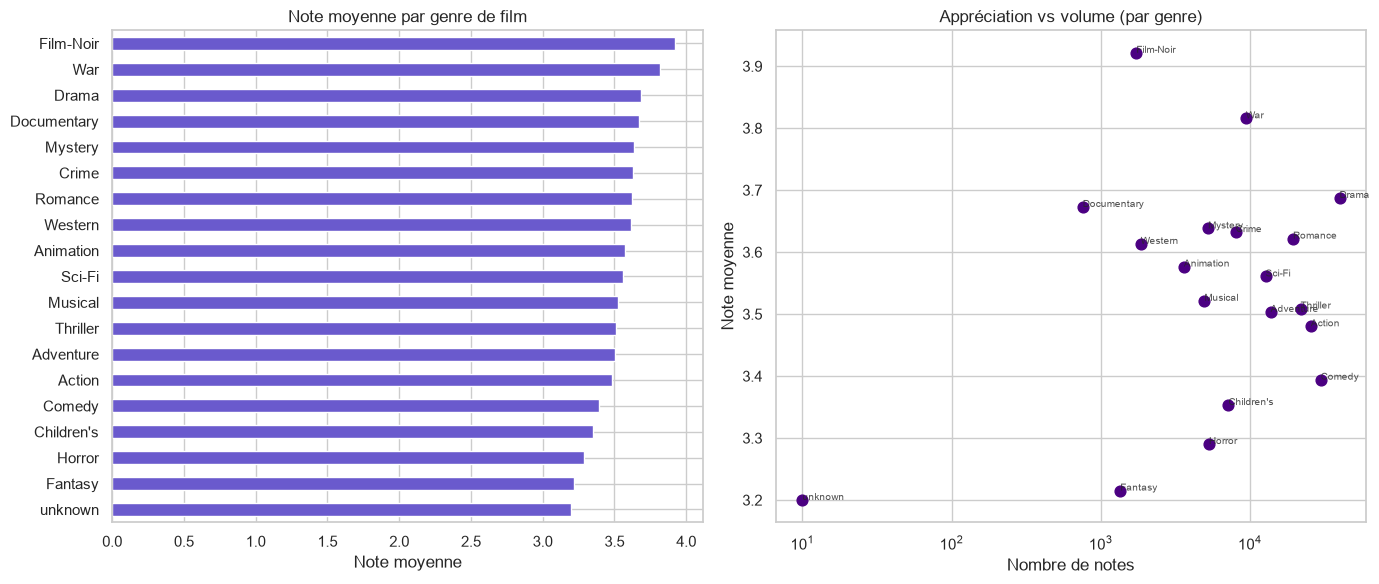

In [12]:
genre_ratings = {}
for g in GENRES:
    mask = df[g] == 1
    if mask.any():
        genre_ratings[g] = {
            "n_notes": int(mask.sum()),
            "note_moyenne": df.loc[mask, "rating"].mean(),
            "note_mediane": df.loc[mask, "rating"].median(),
            "note_std": df.loc[mask, "rating"].std(),
        }

by_film_genre = pd.DataFrame(genre_ratings).T.sort_values("note_moyenne", ascending=False)
display(by_film_genre.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
by_film_genre["note_moyenne"].sort_values().plot(kind="barh", ax=axes[0], color="slateblue")
axes[0].set_title("Note moyenne par genre de film")
axes[0].set_xlabel("Note moyenne")

# Attention au volume : un genre rare peut avoir une moyenne trompeuse
axes[1].scatter(by_film_genre["n_notes"], by_film_genre["note_moyenne"], s=60, color="indigo")
for name, row in by_film_genre.iterrows():
    axes[1].annotate(name, (row["n_notes"], row["note_moyenne"]), fontsize=7, alpha=0.8)
axes[1].set_xlabel("Nombre de notes")
axes[1].set_ylabel("Note moyenne")
axes[1].set_title("Appréciation vs volume (par genre)")
axes[1].set_xscale("log")
plt.tight_layout()
plt.show()

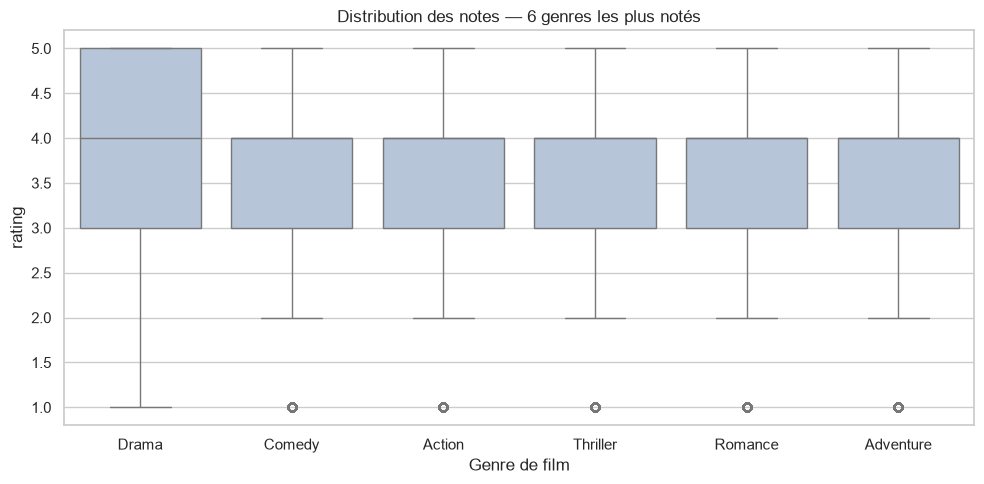

In [13]:
top_genres = genre_summary.nlargest(6, "n_notes").index.tolist()
rows = []
for g in top_genres:
    sub = df.loc[df[g] == 1, ["rating"]].copy()
    sub["genre_film"] = g
    rows.append(sub)
box_genre = pd.concat(rows, ignore_index=True)

plt.figure(figsize=(10, 5))
sns.boxplot(data=box_genre, x="genre_film", y="rating", color="lightsteelblue")
plt.title("Distribution des notes — 6 genres les plus notés")
plt.xlabel("Genre de film")
plt.tight_layout()
plt.show()

## 6. Appréciation selon l’âge, le sexe et le métier

`groupby` pour comparer les groupes — un facteur à la fois, puis lectures croisées.

,n_notes,n_users,note_moyenne,note_mediane,note_std
age_bin,,,,,
≤17,2491,36,3.424,4.0,1.227
18-24,24060,198,3.474,4.0,1.174
25-34,35444,310,3.488,4.0,1.137
35-44,19591,194,3.588,4.0,1.076
45-54,12780,142,3.627,4.0,1.079
55+,5634,63,3.655,4.0,1.036


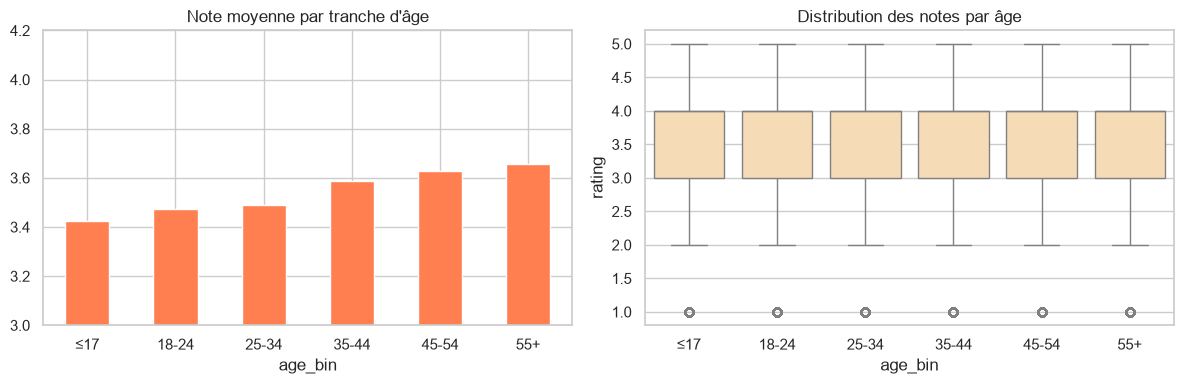

In [14]:
by_age = (
    df.groupby("age_bin", observed=True)
      .agg(
          n_notes=("rating", "size"),
          n_users=("user_id", "nunique"),
          note_moyenne=("rating", "mean"),
          note_mediane=("rating", "median"),
          note_std=("rating", "std"),
      )
)
display(by_age.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_age["note_moyenne"].plot(kind="bar", ax=axes[0], color="coral", ylim=(3, 4.2))
axes[0].set_title("Note moyenne par tranche d'âge")
axes[0].tick_params(axis="x", rotation=0)
sns.boxplot(data=df, x="age_bin", y="rating", ax=axes[1], color="navajowhite")
axes[1].set_title("Distribution des notes par âge")
plt.tight_layout()
plt.show()

,n_notes,n_users,note_moyenne,note_mediane,note_std
gender,,,,,
F,25740,273,3.532,4.0,1.171
M,74260,670,3.529,4.0,1.110


C:\Users\tombo\AppData\Local\Temp\ipykernel_20132\2773845219.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="gender", y="rating", ax=axes[1], palette=["#4C72B0", "#DD8452"])


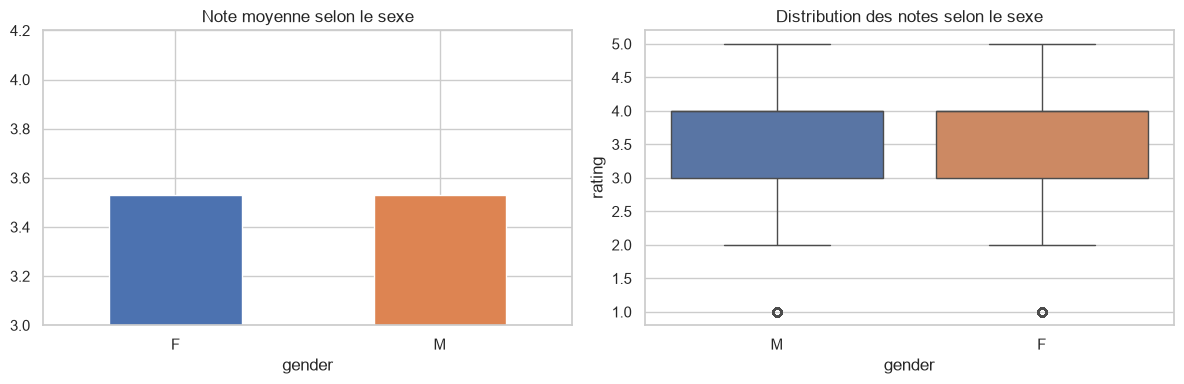

In [15]:
by_gender = (
    df.groupby("gender")
      .agg(
          n_notes=("rating", "size"),
          n_users=("user_id", "nunique"),
          note_moyenne=("rating", "mean"),
          note_mediane=("rating", "median"),
          note_std=("rating", "std"),
      )
)
display(by_gender.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_gender["note_moyenne"].plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"], ylim=(3, 4.2))
axes[0].set_title("Note moyenne selon le sexe")
axes[0].tick_params(axis="x", rotation=0)
sns.boxplot(data=df, x="gender", y="rating", ax=axes[1], palette=["#4C72B0", "#DD8452"])
axes[1].set_title("Distribution des notes selon le sexe")
plt.tight_layout()
plt.show()

,n_notes,n_users,note_moyenne,note_mediane,note_std
occupation,,,,,
none,901,9,3.779,4.0,1.084
lawyer,1345,12,3.735,4.0,1.098
doctor,540,7,3.689,4.0,0.963
educator,9442,95,3.671,4.0,1.077
artist,2308,28,3.653,4.0,1.176
administrator,7479,79,3.636,4.0,1.088
scientist,2058,31,3.611,4.0,1.014
salesman,856,12,3.583,4.0,1.183
programmer,7801,66,3.568,4.0,1.117


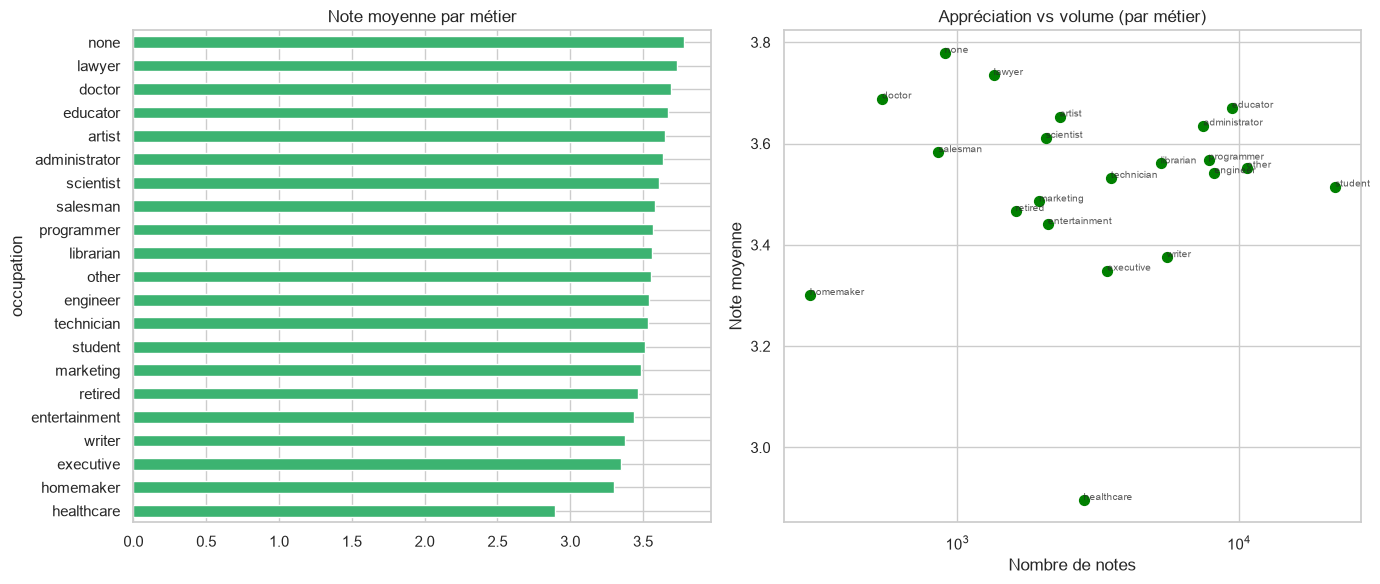

In [16]:
by_occupation = (
    df.groupby("occupation")
      .agg(
          n_notes=("rating", "size"),
          n_users=("user_id", "nunique"),
          note_moyenne=("rating", "mean"),
          note_mediane=("rating", "median"),
          note_std=("rating", "std"),
      )
      .sort_values("note_moyenne", ascending=False)
)
display(by_occupation.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
by_occupation["note_moyenne"].sort_values().plot(kind="barh", ax=axes[0], color="mediumseagreen")
axes[0].set_title("Note moyenne par métier")
axes[1].scatter(by_occupation["n_notes"], by_occupation["note_moyenne"], s=50, color="green")
for name, row in by_occupation.iterrows():
    axes[1].annotate(name, (row["n_notes"], row["note_moyenne"]), fontsize=7, alpha=0.75)
axes[1].set_xscale("log")
axes[1].set_xlabel("Nombre de notes")
axes[1].set_ylabel("Note moyenne")
axes[1].set_title("Appréciation vs volume (par métier)")
plt.tight_layout()
plt.show()

## 7. Croisements — qui apprécie quoi ?

Tableaux / heatmaps : genre de film × âge, genre × sexe, métier × sexe.

gender,F,M,ecart_F_M
Film-Noir,3.740,3.973,-0.233
War,3.781,3.826,-0.045
Drama,3.662,3.697,-0.035
Documentary,3.615,3.692,-0.077
Mystery,3.560,3.664,-0.104
Crime,3.556,3.654,-0.098
Romance,3.656,3.607,0.049
Western,3.515,3.638,-0.123
Animation,3.627,3.557,0.070
Sci-Fi,3.498,3.577,-0.079


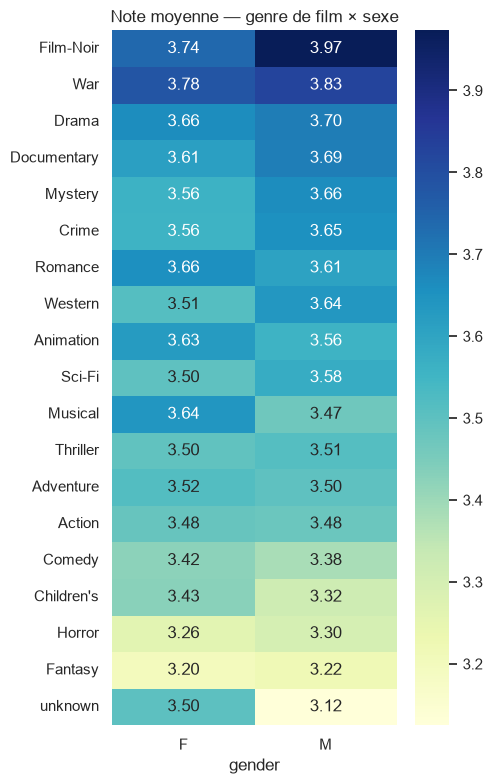

In [17]:
rows = []
for g in GENRES:
    sub = df.loc[df[g] == 1].groupby("gender")["rating"].mean()
    for gender, val in sub.items():
        rows.append({"genre_film": g, "gender": gender, "note_moyenne": val})
pivot_genre_gender = (
    pd.DataFrame(rows)
    .pivot(index="genre_film", columns="gender", values="note_moyenne")
    .reindex(by_film_genre.index)
)
pivot_genre_gender["ecart_F_M"] = pivot_genre_gender.get("F") - pivot_genre_gender.get("M")
display(pivot_genre_gender.round(3))

plt.figure(figsize=(5, 8))
sns.heatmap(pivot_genre_gender[["F", "M"]], annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Note moyenne — genre de film × sexe")
plt.tight_layout()
plt.show()

age_bin,18-24,25-34,35-44,45-54,55+,≤17
genre_film,,,,,,
Animation,3.590,3.586,3.524,3.640,3.644,3.469
Crime,3.642,3.608,3.614,3.684,3.718,3.531
Documentary,3.667,3.697,3.793,3.630,3.536,3.000
Drama,3.641,3.647,3.743,3.762,3.745,3.594
Film-Noir,3.787,3.871,3.990,4.070,4.012,3.500
Mystery,3.502,3.565,3.751,3.775,3.806,3.536
Romance,3.608,3.587,3.644,3.703,3.618,3.625
Sci-Fi,3.537,3.518,3.600,3.621,3.633,3.775
War,3.789,3.752,3.855,3.900,3.918,3.859


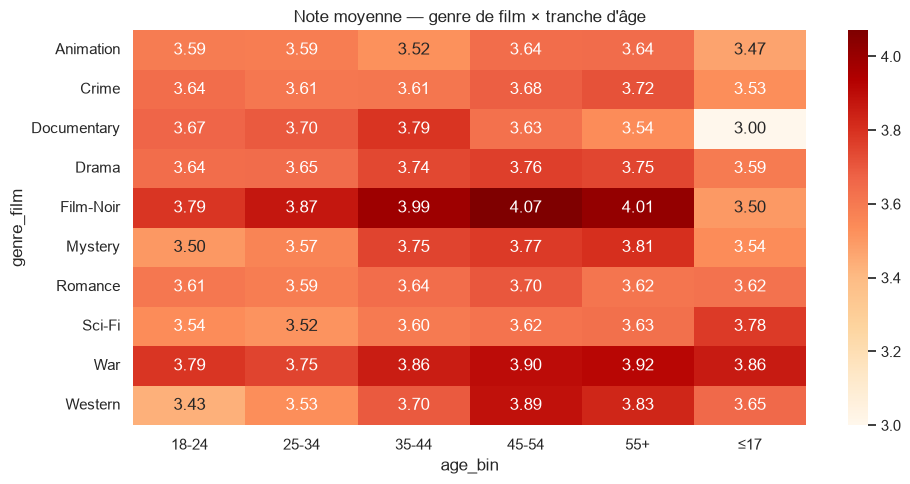

In [18]:
top_genres_for_age = by_film_genre.head(10).index.tolist()
rows = []
for g in top_genres_for_age:
    sub = df.loc[df[g] == 1].groupby("age_bin", observed=True)["rating"].mean()
    for age_bin, val in sub.items():
        rows.append({"genre_film": g, "age_bin": age_bin, "note_moyenne": val})

pivot_genre_age = pd.DataFrame(rows).pivot(index="genre_film", columns="age_bin", values="note_moyenne")
display(pivot_genre_age.round(3))

plt.figure(figsize=(10, 5))
sns.heatmap(pivot_genre_age, annot=True, fmt=".2f", cmap="OrRd")
plt.title("Note moyenne — genre de film × tranche d'âge")
plt.tight_layout()
plt.show()

gender,F,M
occupation,,
administrator,3.782,3.555
artist,3.347,3.876
doctor,NaN,3.689
educator,3.699,3.660
engineer,3.752,3.538
entertainment,3.449,3.440
executive,3.774,3.320
healthcare,2.736,3.640
homemaker,3.279,3.500


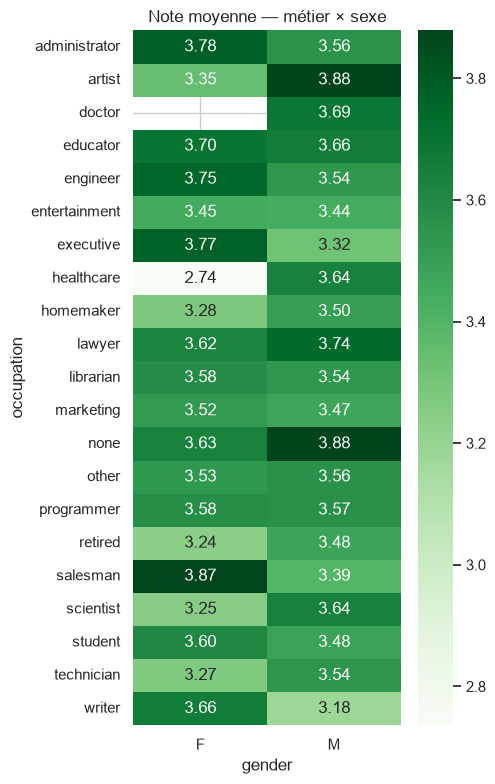

Effectifs gender × rating


rating,1,2,3,4,5
gender,,,,,
F,1894,2784,6784,8303,5975
M,4216,8586,20361,25871,15226


Proportions (par ligne)


rating,1,2,3,4,5
gender,,,,,
F,0.074,0.108,0.264,0.323,0.232
M,0.057,0.116,0.274,0.348,0.205


In [19]:
ct_occ_gender = (
    df.groupby(["occupation", "gender"])["rating"]
      .mean()
      .unstack("gender")
)
display(ct_occ_gender.round(3))

plt.figure(figsize=(5, 8))
sns.heatmap(ct_occ_gender, annot=True, fmt=".2f", cmap="Greens")
plt.title("Note moyenne — métier × sexe")
plt.tight_layout()
plt.show()

# Tableau croisé classique : répartition des notes (effectifs) selon le sexe
ct_counts = pd.crosstab(df["gender"], df["rating"])
ct_props = pd.crosstab(df["gender"], df["rating"], normalize="index")
print("Effectifs gender × rating")
display(ct_counts)
print("Proportions (par ligne)")
display(ct_props.round(3))

## 8. Corrélations

On construit des **indicateurs numériques** (niveau utilisateur et niveau film), puis :

- matrices de corrélation (Pearson / Spearman) ;
- scatterplots commentés ;
- corrélation entre part de notes par genre et note moyenne (goûts).

> Une corrélation ne prouve pas une causalité — elle mesure une association linéaire (Pearson) ou monotone (Spearman).

,age,n_notes,note_moyenne,note_std,part_Drama,part_Comedy,part_Action,part_Romance,part_Sci-Fi,part_Horror
count,943.000,943.000,943.000,943.000,943.000,943.000,943.000,943.000,943.000,943.000
mean,34.052,106.045,3.588,1.020,0.417,0.277,0.261,0.206,0.129,0.052
std,12.193,100.932,0.445,0.205,0.134,0.112,0.129,0.080,0.074,0.067
min,7.000,20.000,1.492,0.344,0.040,0.000,0.000,0.029,0.000,0.000
25%,25.000,33.000,3.323,0.876,0.323,0.208,0.176,0.156,0.077,0.019
50%,31.000,65.000,3.621,1.012,0.409,0.273,0.250,0.195,0.122,0.038
75%,43.000,148.000,3.870,1.140,0.500,0.333,0.322,0.242,0.170,0.064
max,73.000,737.000,4.870,1.750,0.900,0.926,0.957,0.913,0.583,0.758


Corrélation de Pearson (utilisateurs)


,age,n_notes,note_moyenne,note_std,part_Drama,part_Comedy,part_Action,part_Romance,part_Sci-Fi,part_Horror
age,1.000,-0.093,0.093,-0.128,0.354,-0.076,-0.227,0.100,-0.244,-0.202
n_notes,-0.093,1.000,-0.138,-0.001,-0.141,0.197,-0.040,-0.155,-0.019,0.023
note_moyenne,0.093,-0.138,1.000,-0.400,0.124,-0.045,-0.066,0.104,0.014,-0.069
note_std,-0.128,-0.001,-0.400,1.000,-0.064,0.057,0.004,-0.024,-0.005,0.025
part_Drama,0.354,-0.141,0.124,-0.064,1.000,-0.335,-0.593,0.250,-0.499,-0.292
part_Comedy,-0.076,0.197,-0.045,0.057,-0.335,1.000,-0.237,0.251,-0.155,-0.241
part_Action,-0.227,-0.040,-0.066,0.004,-0.593,-0.237,1.000,-0.276,0.688,0.081
part_Romance,0.100,-0.155,0.104,-0.024,0.250,0.251,-0.276,1.000,-0.271,-0.327
part_Sci-Fi,-0.244,-0.019,0.014,-0.005,-0.499,-0.155,0.688,-0.271,1.000,0.143
part_Horror,-0.202,0.023,-0.069,0.025,-0.292,-0.241,0.081,-0.327,0.143,1.000


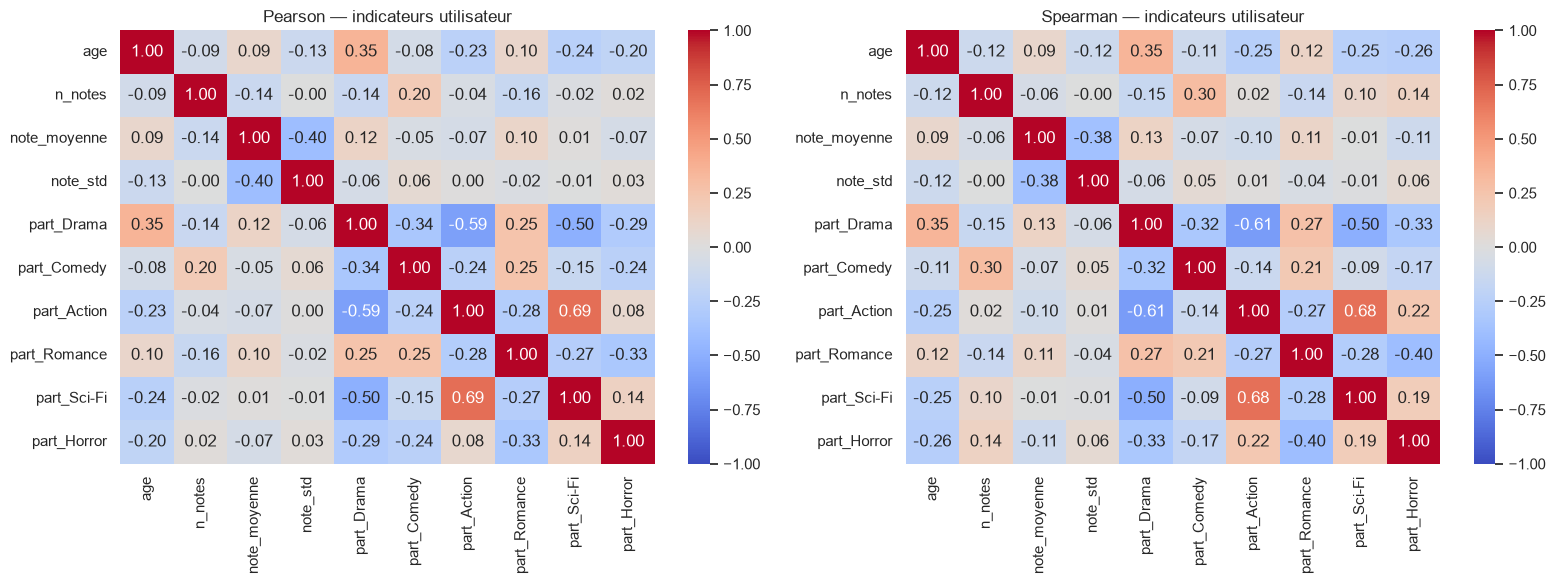

In [20]:
# --- Niveau utilisateur ---
user_corr = user_activity[["age", "n_notes", "note_moyenne", "note_std"]].copy()

# Part des notes données à quelques grands genres (proxy de goûts)
for g in ["Drama", "Comedy", "Action", "Romance", "Sci-Fi", "Horror"]:
    # moyenne du flag genre = proportion des notes de l'user sur ce genre
    user_corr[f"part_{g}"] = df.groupby("user_id")[g].mean().reindex(user_activity["user_id"]).values

display(user_corr.describe().round(3))

corr_pearson = user_corr.corr(method="pearson")
corr_spearman = user_corr.corr(method="spearman")

print("Corrélation de Pearson (utilisateurs)")
display(corr_pearson.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson — indicateurs utilisateur")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman — indicateurs utilisateur")
plt.tight_layout()
plt.show()

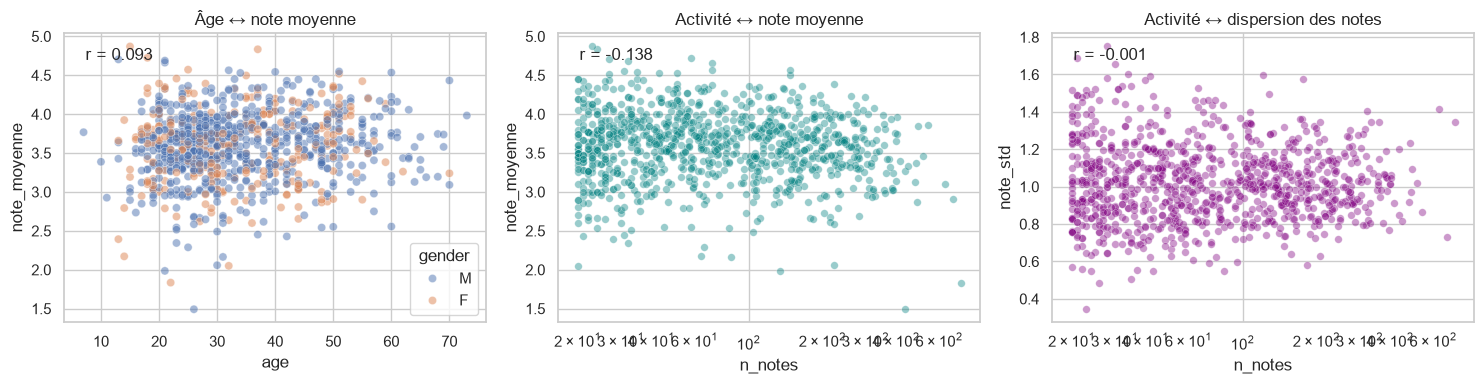

Corrélation âge ↔ note moyenne     : 0.093
Corrélation activité ↔ note moyenne : -0.138
Corrélation activité ↔ écart-type   : -0.001


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.scatterplot(
    data=user_activity, x="age", y="note_moyenne", hue="gender",
    alpha=0.5, s=35, ax=axes[0],
)
axes[0].set_title("Âge ↔ note moyenne")
r_age = user_activity["age"].corr(user_activity["note_moyenne"])
axes[0].text(0.05, 0.95, f"r = {r_age:.3f}", transform=axes[0].transAxes, va="top")

sns.scatterplot(
    data=user_activity, x="n_notes", y="note_moyenne",
    alpha=0.4, s=30, ax=axes[1], color="teal",
)
axes[1].set_xscale("log")
axes[1].set_title("Activité ↔ note moyenne")
r_act = user_activity["n_notes"].corr(user_activity["note_moyenne"])
axes[1].text(0.05,.95, f"r = {r_act:.3f}", transform=axes[1].transAxes, va="top")

sns.scatterplot(
    data=user_activity, x="n_notes", y="note_std",
    alpha=0.4, s=30, ax=axes[2], color="purple",
)
axes[2].set_xscale("log")
axes[2].set_title("Activité ↔ dispersion des notes")
r_std = user_activity["n_notes"].corr(user_activity["note_std"])
axes[2].text(0.05, 0.95, f"r = {r_std:.3f}", transform=axes[2].transAxes, va="top")

plt.tight_layout()
plt.show()

print(f"Corrélation âge ↔ note moyenne     : {r_age:.3f}")
print(f"Corrélation activité ↔ note moyenne : {r_act:.3f}")
print(f"Corrélation activité ↔ écart-type   : {r_std:.3f}")

Corrélation (Pearson) entre part de notes sur un genre et note moyenne de l'utilisateur :


,corr_avec_note_moyenne
part_Horror,-0.069
part_Action,-0.066
part_Comedy,-0.045
part_Sci-Fi,0.014
part_Romance,0.104
part_Drama,0.124


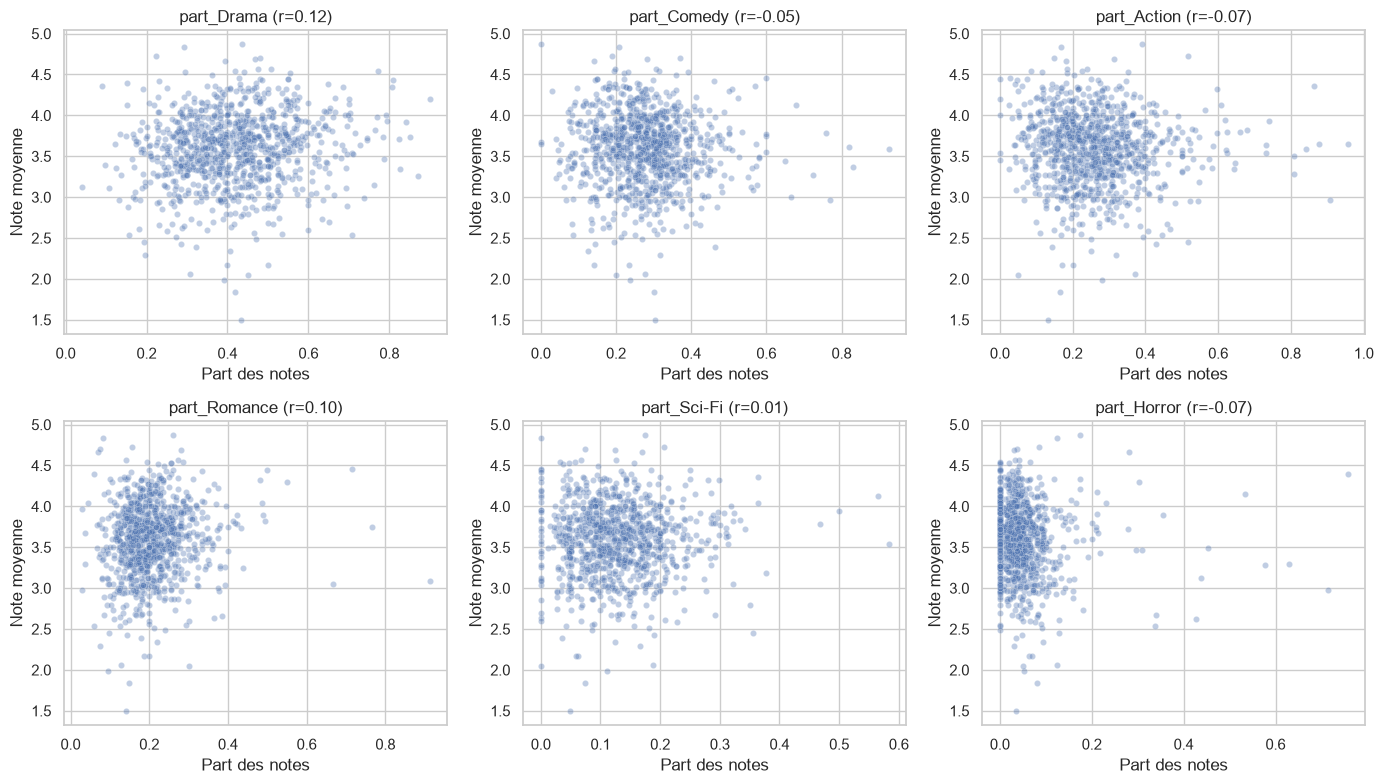

In [22]:
# Zoom : goûts (part de notes sur un genre) ↔ note moyenne globale de l'utilisateur
taste_cols = [c for c in user_corr.columns if c.startswith("part_")]
taste_vs_rating = user_corr[taste_cols + ["note_moyenne"]].corr()["note_moyenne"].drop("note_moyenne")
print("Corrélation (Pearson) entre part de notes sur un genre et note moyenne de l'utilisateur :")
display(taste_vs_rating.sort_values().to_frame("corr_avec_note_moyenne").round(3))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for i, col in enumerate(taste_cols):
    sns.scatterplot(x=user_corr[col], y=user_corr["note_moyenne"], ax=axes[i], alpha=0.35, s=20)
    r = user_corr[col].corr(user_corr["note_moyenne"])
    axes[i].set_title(f"{col} (r={r:.2f})")
    axes[i].set_xlabel("Part des notes")
    axes[i].set_ylabel("Note moyenne")
plt.tight_layout()
plt.show()

Indicateurs film :


,n_notes,note_moyenne,note_std,release_year,n_genres
count,1540.000,1540.000,1540.000,1540.000,1540.000
mean,64.838,3.147,1.057,1989.468,1.752
std,81.939,0.677,0.293,14.043,0.882
min,2.000,1.000,0.000,1922.000,1.000
25%,9.000,2.702,0.916,1993.000,1.000
50%,32.000,3.200,1.034,1995.000,2.000
75%,87.000,3.661,1.170,1996.000,2.000
max,583.000,5.000,2.828,1998.000,6.000


,n_notes,note_moyenne,note_std,release_year,n_genres
n_notes,1.000,0.449,-0.152,-0.085,0.337
note_moyenne,0.449,1.000,-0.099,-0.324,0.096
note_std,-0.152,-0.099,1.000,0.170,-0.052
release_year,-0.085,-0.324,0.170,1.000,-0.055
n_genres,0.337,0.096,-0.052,-0.055,1.000


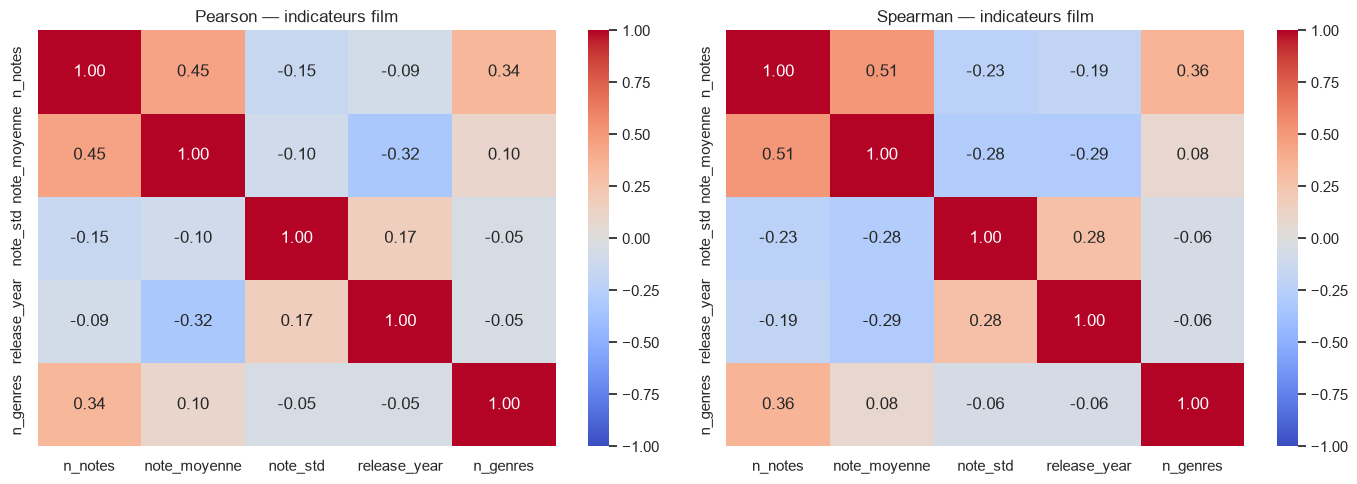

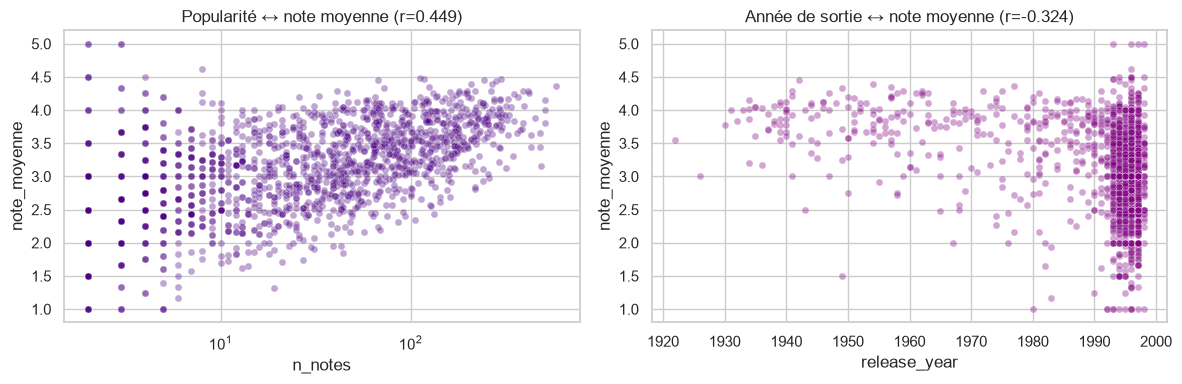

Corrélation popularité ↔ note moyenne : 0.449
Corrélation année ↔ note moyenne      : -0.324


In [23]:
# --- Niveau film ---
film_level = film_popularity.merge(
    films[["movie_id"] + GENRES],
    left_on="item_id",
    right_on="movie_id",
    how="left",
)
film_level["n_genres"] = film_level[GENRES].sum(axis=1)
film_corr = film_level[["n_notes", "note_moyenne", "note_std", "release_year", "n_genres"]].dropna()

print("Indicateurs film :")
display(film_corr.describe().round(3))

corr_film_p = film_corr.corr(method="pearson")
corr_film_s = film_corr.corr(method="spearman")
display(corr_film_p.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(corr_film_p, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson — indicateurs film")
sns.heatmap(corr_film_s, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman — indicateurs film")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=film_corr, x="n_notes", y="note_moyenne", alpha=0.35, s=25, ax=axes[0], color="indigo")
axes[0].set_xscale("log")
r1 = film_corr["n_notes"].corr(film_corr["note_moyenne"])
axes[0].set_title(f"Popularité ↔ note moyenne (r={r1:.3f})")

sns.scatterplot(data=film_corr, x="release_year", y="note_moyenne", alpha=0.35, s=25, ax=axes[1], color="purple")
r2 = film_corr["release_year"].corr(film_corr["note_moyenne"])
axes[1].set_title(f"Année de sortie ↔ note moyenne (r={r2:.3f})")
plt.tight_layout()
plt.show()

print(f"Corrélation popularité ↔ note moyenne : {r1:.3f}")
print(f"Corrélation année ↔ note moyenne      : {r2:.3f}")


## 9. Synthèse

À compléter après exécution des cellules.

| Bloc | Ce qu’on regarde | Constats / corrélations notables |
| --- | --- | --- |
| Vue d’ensemble | tailles, manquants, volumes | |
| Numérique | rating, âge, activité | |
| Catégoriel | sexe, métier, genres (rares) | |
| Temps | évolution, saisonnalité | |
| Genre de film | note moyenne vs volume | |
| Âge / sexe / métier | différences d’appréciation | |
| Croisements | qui aime quels genres | |
| Corrélations user | âge, activité, parts de genres | |
| Corrélations film | popularité, année, n_genres | |

**Rappel :** une corrélation forte n’implique pas de causalité ; toujours croiser avec les effectifs (genres / métiers rares).

## 4. Qu'est-ce qui manque ?

L'EDA décrit les tendances observées dans MovieLens 100k, mais elle ne permet pas de généraliser les résultats à toute la population ni d'expliquer les causes.

### Biais

- **Biais de sélection** : les utilisateurs et les films présents dans MovieLens ne représentent pas nécessairement tous les publics ni tout le catalogue.
- **Biais de participation** : nous observons uniquement les notes déposées. Ne pas noter un film ne signifie pas forcément ne pas l'aimer.
- **Biais de popularité** : les films très connus ont davantage de notes et pèsent davantage dans les analyses globales.

### Limites des données

- Le jeu contient des notes, des informations déclarées sur les utilisateurs et des genres, mais pas le contexte de visionnage, les recommandations reçues, les goûts non exprimés ou les raisons d'une note.
- Les données sont historiques et couvrent une période limitée ; les comportements et les films ont évolué depuis.
- Certaines catégories sont peu représentées. Une moyenne calculée sur très peu de notes doit donc être interprétée avec prudence.

### Représentativité

Les résultats décrivent les utilisateurs de ce jeu de données, pas la population générale. Les comparaisons entre groupes doivent tenir compte des effectifs, de l'âge, du sexe, du métier et du nombre de notes par personne.

### Causalité

Une différence de moyenne ou une corrélation ne prouve pas qu'une variable en cause une autre. Par exemple, une association entre l'âge et les notes peut être liée au genre des films vus, à la popularité des films ou à d'autres variables non observées. Il faudrait une étude contrôlée ou une méthode causale adaptée pour conclure à un effet.


In [24]:
print("=== Contrôles pour interpréter l'EDA ===")
print(f"Utilisateurs observés : {df['user_id'].nunique():,}")
print(f"Films observés        : {df['item_id'].nunique():,}")
print(f"Notes observées       : {len(df):,}")

notes_par_film = df.groupby("item_id").size()
print(f"Films avec moins de 10 notes : {(notes_par_film < 10).sum():,}")
print(f"Film le plus noté             : {notes_par_film.max():,} notes")

print("\nConclusion : les résultats sont descriptifs et doivent être interprétés avec prudence.")

=== Contrôles pour interpréter l'EDA ===
Utilisateurs observés : 943
Films observés        : 1,682
Notes observées       : 100,000
Films avec moins de 10 notes : 530
Film le plus noté             : 583 notes

Conclusion : les résultats sont descriptifs et doivent être interprétés avec prudence.
